<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/05_imputation_tuning_ansel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: impute missing inputs instead of dropping rows, compare the two, and re-tune the tree and k-NN

Notebook 04 dropped every game with a missing input: 3,649 of 21,631 games (16.9%). This notebook keeps almost all of them, fills in their missing inputs, and answers four questions:

1. How much is missing, and are the games with gaps different from the rest?
2. Which of five imputers works best, judged by 5-fold cross-validation inside a `Pipeline`?
3. With the chosen imputer, what are the best settings for the regression tree and k-NN (sweeps and grid searches)?
4. Does imputing beat dropping, judged like-for-like, and what do the test rows say when scored once at the end?

Every choice below was made by Ansel Weng, one decision at a time, before any code was written:

| # | Decision | Choice |
| --- | --- | --- |
| 2 | Rows | Drop the 195 games with no year (year is the strongest input in notebook 04, and notebooks 03 and 12 also leave them out) and the games missing 4 or more of the 8 numeric inputs (most of their row would be invented). Impute everything else. |
| 3 | Inputs | Notebook 04's: 8 numeric inputs, plus 0/1 columns for the 20 most common mechanics and 15 most common categories, counted on training rows |
| 3b | Missing mechanic or category list | 0 in the 0/1 columns, plus two flags, `mech_list_missing` and `cat_list_missing`, so the model can tell "none of these" from "unknown" |
| 4 | Imputers | mean, median, median + indicator, k-NN imputer (k = 5), iterative; each scored with linear regression, the tree and k-NN at notebook 04's tuned settings |
| 4d | Picking the imputer | Imputers within **0.005 RMSE** of the best, for **all three** models, count as tied; among tied ones the simplest wins (median = mean < median + indicator < k-NN < iterative; median preferred over mean) |
| 5 | Split | Complete games split exactly as notebook 04 (`test_size=0.3, random_state=1`), incomplete games split the same way, then combined. The drop approach therefore uses notebook 04's exact rows. |
| 5b | Test sets | complete test games (like-for-like), all test games, and the test games with a missing input |
| 5c | Drop approach | re-tuned with the same grids, on complete training games |
| 6 | Tree | `max_depth` and `min_samples_leaf` on notebook 04's grid; sweeps from cross-validation: depth at two leaf sizes, leaf size at the tuned depth |
| 7 | k-NN | `n_neighbors` (5 to 75, notebook 04's values), `weights` and `p`; `StandardScaler` in the pipeline; k sweeps for both weightings |
| 8 | Cross-validation | one fixed `KFold(n_splits=5, shuffle=True, random_state=0)` everywhere; mean and standard deviation of RMSE |
| 9 | Drop vs impute | decided by cross-validation on the complete validation games only; impute wins unless it is more than 0.005 RMSE worse |

Ground rules: same loading cell as notebooks 02 to 04; RMSE with MAE and R² next to `DummyRegressor`; no post-release column (`rank`, `bayes_average`, `users_rated`, `owned`, `trading`, `wanting`, `wishing`) as an input; every imputer and scaler fitted on training rows only, inside a `Pipeline`; the test rows scored once, at the end.

In [1]:
# --- Ansel Weng: task 1, impute missing inputs instead of dropping rows, compare the two, and re-tune the tree and k-NN by cross-validation ---
# [AI-assisted] Claude Code, 2026-11-10. Every code and markdown cell in this notebook was generated with Claude Code from Ansel Weng's decisions, notebook 04 and the course labs; reviewed and edited by Ansel Weng.
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer  # noqa: F401, IterativeImputer is still marked experimental in scikit-learn
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)  # the iterative imputer warns when it stops at max_iter; its score is what we compare

## 1. Load the data

In [2]:
# [AI-assisted] Claude Code, 2026-11-10. Same loading cell as notebooks 02 to 04; reviewed and edited by Ansel Weng.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

(21631, 24)


In [3]:
# [AI-assisted] Claude Code, 2026-11-10. Figure folder helper, as in notebook 04; reviewed and edited by Ansel Weng.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

## 2. How much is missing, and are the games with gaps different?

The inputs are notebook 04's. The target, `average`, is never missing. A game is missing `n_mechanics` exactly when its mechanic list is missing (and likewise for categories), so counting gaps over the 8 numeric inputs counts each missing list once.

In [4]:
# [AI-assisted] Claude Code, 2026-11-10. Missing cells per input and missing inputs per game; reviewed and edited by Ansel Weng.
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
assert (games["n_mechanics"].isna() == games["boardgamemechanic"].isna()).all()
assert (games["n_categories"].isna() == games["boardgamecategory"].isna()).all()
assert games["average"].notna().all()

miss = games[numeric_cols].isna()
n_missing = miss.sum(axis=1)
print("games with at least one missing input:", int((n_missing > 0).sum()), f"of {len(games):,} ({100 * (n_missing > 0).mean():.1f}%)")
print("missing inputs per game:", n_missing.value_counts().sort_index().to_dict())
pd.DataFrame({"games missing": miss.sum(), "share missing (%)": (100 * miss.mean()).round(2)}).sort_values("games missing", ascending=False)

games with at least one missing input: 3649 of 21,631 (16.9%)
missing inputs per game: {0: 17982, 1: 2759, 2: 560, 3: 252, 4: 52, 5: 16, 6: 4, 7: 2, 8: 4}


,games missing,share missing (%)
n_mechanics,1590,7.35
minage,1301,6.01
maxplaytime,774,3.58
minplaytime,642,2.97
n_categories,283,1.31
yearpublished,195,0.90
maxplayers,164,0.76
minplayers,44,0.20


In [5]:
# [AI-assisted] Claude Code, 2026-11-10. Compare complete games with games that have a gap; users_rated only describes the two groups and is never an input; reviewed and edited by Ansel Weng.
has_gap = np.where(n_missing > 0, "at least one input missing", "every input known")
groups = games.groupby(has_gap).agg(
    games=("average", "size"),
    mean_rating=("average", "mean"),
    sd_rating=("average", "std"),
    median_raters=("users_rated", "median"),
    median_year=("yearpublished", "median"),
)
groups.round(3)

,games,mean_rating,sd_rating,median_raters,median_year
at least one input missing,3649,6.171,1.045,64.0,2009.0
every input known,17982,6.467,0.896,148.0,2012.0


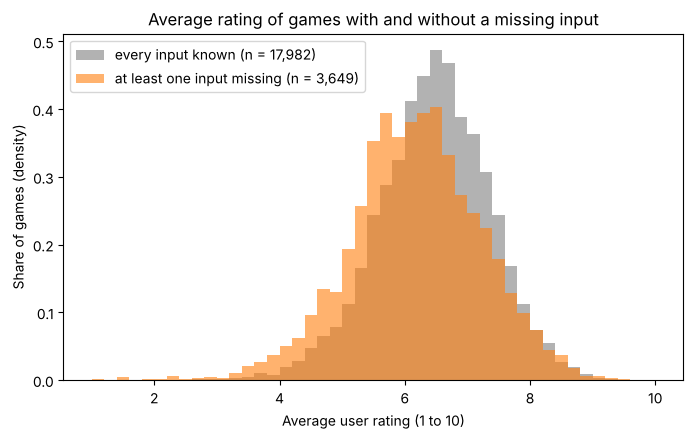

In [6]:
# [AI-assisted] Claude Code, 2026-11-10. Rating distribution of the two groups; reviewed and edited by Ansel Weng.
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(1, 10, 46)
for label, colour in [("every input known", "0.5"), ("at least one input missing", "tab:orange")]:
    ax.hist(games.loc[has_gap == label, "average"], bins=bins, density=True, alpha=0.6, color=colour,
            label=f"{label} (n = {(has_gap == label).sum():,})")
ax.set_title("Average rating of games with and without a missing input")
ax.set_xlabel("Average user rating (1 to 10)")
ax.set_ylabel("Share of games (density)")
ax.legend()
save("05_rating_by_missingness.png")
plt.show()

**Takeaway:** 3,649 of 21,631 games (16.9%) have at least one missing input, most often the mechanic list (7.35%) and minimum age (6.01%). That is well above the 5% the course directives (§5.3) give as the point where dropping rows should be questioned. The incomplete games are **not a random sample**. Their mean rating is 6.17, against 6.47 for complete games. Their ratings are more spread out (standard deviation 1.05 against 0.90), and they have fewer raters (median 64 against 148). Dropping them leaves a catalogue tilted towards better-rated, better-known games, and a model that has never seen the kind of game most likely to arrive with an incomplete listing.

## 3. Which games are kept

Decision 2: leave out the games with no year of publication, and the games missing 4 or more of the 8 numeric inputs. Everything else is kept, and its gaps are imputed.

In [7]:
# [AI-assisted] Claude Code, 2026-11-10. Apply the row rule and count what it removes; reviewed and edited by Ansel Weng.
no_year = games["yearpublished"].isna()
heavy = n_missing >= 4
keep = ~(no_year | heavy)
print("no year:", int(no_year.sum()), "| missing 4+ of 8 inputs:", int(heavy.sum()), "| both:", int((no_year & heavy).sum()))
print("dropped:", int((~keep).sum()), f"({100 * (~keep).mean():.2f}%) | kept:", int(keep.sum()))

data = games[keep].copy()
data["complete"] = data[numeric_cols].notna().all(axis=1)
complete_rows = data[data["complete"]].reset_index(drop=True)
incomplete_rows = data[~data["complete"]].reset_index(drop=True)
print("kept games with every input known:", len(complete_rows), "| kept games with a gap to impute:", len(incomplete_rows))
print("gaps per kept incomplete game:", incomplete_rows[numeric_cols].isna().sum(axis=1).value_counts().sort_index().to_dict())

no year: 195 | missing 4+ of 8 inputs: 78 | both: 21
dropped: 252 (1.16%) | kept: 21379
kept games with every input known: 17982 | kept games with a gap to impute: 3397
gaps per kept incomplete game: {1: 2644, 2: 517, 3: 236}


## 4. One split, built so the drop approach is notebook 04 exactly

Decision 5a: the complete games are split with `train_test_split(test_size=0.3, random_state=1)` exactly as notebook 04 split them, and the incomplete games are split the same way on their own. The two halves are then combined.

- The **drop** approach uses only the complete games in each half, which are notebook 04's 12,587 training and 5,395 test games (checked below).
- The **impute** approach uses every kept game.
- Both halves hold exactly 30% of the complete and 30% of the incomplete games, so the test set cannot end up with unusually many or few incomplete games by chance.

In [8]:
# [AI-assisted] Claude Code, 2026-11-10. Two-part split and a check that the complete part reproduces notebook 04's split; reviewed and edited by Ansel Weng.
train_c, test_c = train_test_split(complete_rows, test_size=0.3, random_state=1)
train_i, test_i = train_test_split(incomplete_rows, test_size=0.3, random_state=1)
train_df = pd.concat([train_c, train_i], ignore_index=True)
test_df = pd.concat([test_c, test_i], ignore_index=True)
y_train, y_test = train_df["average"], test_df["average"]
train_complete, test_complete = train_df["complete"].values, test_df["complete"].values

# Notebook 04's rows and split, rebuilt here, must give the same test games.
nb04_rows = games.dropna(subset=numeric_cols + ["boardgamemechanic", "boardgamecategory", "average"]).reset_index(drop=True)
nb04_train, nb04_test = train_test_split(nb04_rows, test_size=0.3, random_state=1)
assert set(nb04_test["id"]) == set(test_c["id"]) and set(nb04_train["id"]) == set(train_c["id"])

print("training games:", len(train_df), f"({train_complete.sum():,} complete, {(~train_complete).sum():,} with a gap)")
print("test games:", len(test_df), f"({test_complete.sum():,} complete, {(~test_complete).sum():,} with a gap)")
print("complete part matches notebook 04's split: yes")

training games: 14964 (12,587 complete, 2,377 with a gap)
test games: 6415 (5,395 complete, 1,020 with a gap)
complete part matches notebook 04's split: yes


## 5. Inputs

As in notebook 04: log10 of the player counts and play times, the other numeric inputs as they are, and 0/1 columns for the most common mechanics and categories. Decision 3b adds two flags for a missing list. A game with no mechanic list gets 0 in every mechanic column and 1 in `mech_list_missing`; its missing `n_mechanics` is left for the imputer.

Each approach counts "most common" on its own training games (ground rule 5). The mechanic lists come out identical. For categories, the impute approach's 15th most common is World War II, where the drop approach (and notebook 04) has Deduction. The drop approach has no missing lists, so its flags would be constant zeros, and they are left out. That keeps it identical to notebook 04's inputs.

**Leakage check on the two flags (ground rule 4).** A list is missing because nobody filled it in on BoardGameGeek, and obscure games are the least likely to be filled in. Obscurity is partly a result of how a game was received, so the flag may partly stand in for popularity, which is measured after release. On the other hand, a brand-new game's listing would also be incomplete at prediction time. Decision 3b keeps the flags. The feature-importance table in section 11 shows how much the models lean on them.

In [9]:
# [AI-assisted] Claude Code, 2026-11-10. Most common mechanics and categories on each approach's training games, and the input builder; reviewed and edited by Ansel Weng.
N_MECH, N_CAT = 20, 15
log_cols = ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]

def top_entries(frame, column, n):
    return frame[column].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(n).index

def build_inputs(frame, mechanics, categories, flags=True):
    X = frame[numeric_cols].copy()
    for col in log_cols:
        X[col] = np.log10(X[col])                         # log10 of a missing value stays missing for the imputer
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=mechanics, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=categories, fill_value=0).add_prefix("cat_")
    parts = [X, mech, cat]                                # a missing list gives 0 in every 0/1 column
    if flags:
        parts.append(pd.DataFrame({"mech_list_missing": frame["boardgamemechanic"].isna().astype(int),
                                   "cat_list_missing": frame["boardgamecategory"].isna().astype(int)}, index=frame.index))
    return pd.concat(parts, axis=1)

# Impute approach: every training game.
mech_imp, cat_imp = top_entries(train_df, "boardgamemechanic", N_MECH), top_entries(train_df, "boardgamecategory", N_CAT)
X_train = build_inputs(train_df, mech_imp, cat_imp)
X_test = build_inputs(test_df, mech_imp, cat_imp)

# Drop approach: complete training games only, no flags; this is notebook 04's input table.
train_cc, test_cc = train_df[train_complete], test_df[test_complete]
mech_drop, cat_drop = top_entries(train_cc, "boardgamemechanic", N_MECH), top_entries(train_cc, "boardgamecategory", N_CAT)
X_train_drop, y_train_drop = build_inputs(train_cc, mech_drop, cat_drop, flags=False), y_train[train_complete]
X_test_drop, y_test_drop = build_inputs(test_cc, mech_drop, cat_drop, flags=False), y_test[test_complete]

print("impute approach:", X_train.shape[1], "inputs | drop approach:", X_train_drop.shape[1], "inputs")
print("mechanic lists identical:", set(mech_imp) == set(mech_drop))
print("categories only in the impute approach:", sorted(set(cat_imp) - set(cat_drop)), "| only in the drop approach:", sorted(set(cat_drop) - set(cat_imp)))
print("missing cells in the impute training inputs:", int(X_train.isna().sum().sum()))

impute approach: 45 inputs | drop approach: 43 inputs
mechanic lists identical: True
categories only in the impute approach: ['World War II'] | only in the drop approach: ['Deduction']
missing cells in the impute training inputs: 3083


## 6. Which imputer?

Each imputer is the first step of a `Pipeline`, so in every cross-validation fold it is fitted on the four training folds and applied to the fifth:

| Imputer | What fills a gap | Simplicity rank |
| --- | --- | --- |
| median | the column's training median | 1 (preferred over mean when both tie) |
| mean | the column's training mean | 1 |
| median + indicator | the median, plus a 0/1 "was missing" column for each input that has gaps | 2 |
| k-NN imputer | the average of the 5 most similar training games (inputs standardized first, because `KNNImputer` measures raw distance) | 3 |
| iterative | each column predicted from the others by a regression, repeated until stable (`IterativeImputer`) | 4 |

Decision 4c: each imputer is scored with three models held at notebook 04's tuned settings, so that only the imputer changes. These are linear regression, the tree (depth 10, at least 50 games per leaf) and k-NN (k = 30, distance weights, Euclidean). With 3b's flags in place, median + indicator's "`n_mechanics` was missing" column duplicates `mech_list_missing`. That is harmless; its real additions are the indicators for minimum age, play times, player counts and the counts.

In [10]:
# [AI-assisted] Claude Code, 2026-11-10. Imputer and model building blocks, shared by every pipeline in the notebook; reviewed and edited by Ansel Weng.
folds = KFold(n_splits=5, shuffle=True, random_state=0)
IMPUTERS = ["median", "mean", "median + indicator", "k-NN imputer", "iterative"]   # simplest first: the order decision 4d breaks ties by

def imputer_steps(name):
    if name == "mean":
        return [("impute", SimpleImputer(strategy="mean"))]
    if name == "median":
        return [("impute", SimpleImputer(strategy="median"))]
    if name == "median + indicator":
        return [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if name == "k-NN imputer":
        return [("prescale", StandardScaler()), ("impute", KNNImputer(n_neighbors=5))]
    if name == "iterative":
        return [("impute", IterativeImputer(max_iter=10, random_state=0))]
    raise ValueError(name)

def model_steps(name, **params):
    if name == "linear":
        return [("model", LinearRegression(**params))]
    if name == "tree":
        return [("model", DecisionTreeRegressor(random_state=0, **params))]
    if name == "k-NN":
        return [("scale", StandardScaler()), ("model", KNeighborsRegressor(**params))]
    raise ValueError(name)

def pipe(imputer, model, **params):
    steps = (imputer_steps(imputer) if imputer else []) + model_steps(model, **params)
    return Pipeline(steps)

NB04_SETTINGS = {"linear": {}, "tree": {"max_depth": 10, "min_samples_leaf": 50}, "k-NN": {"n_neighbors": 30, "weights": "distance"}}

In [11]:
# [AI-assisted] Claude Code, 2026-11-10. 5-fold cross-validated RMSE for every imputer with every model, on the impute approach's training games; reviewed and edited by Ansel Weng.
rows = []
for imp_name in IMPUTERS:
    for model_name, params in NB04_SETTINGS.items():
        start = time.time()
        scores = -cross_val_score(pipe(imp_name, model_name, **params), X_train, y_train,
                                  cv=folds, scoring="neg_root_mean_squared_error", n_jobs=-1)
        rows.append({"imputer": imp_name, "model": model_name, "CV RMSE": scores.mean(), "CV RMSE sd": scores.std(),
                     "seconds": time.time() - start})
imputer_cv = pd.DataFrame(rows)
imputer_table = imputer_cv.pivot(index="imputer", columns="model", values="CV RMSE").loc[IMPUTERS, ["linear", "tree", "k-NN"]]
imputer_sd = imputer_cv.pivot(index="imputer", columns="model", values="CV RMSE sd").loc[IMPUTERS, ["linear", "tree", "k-NN"]]
imputer_secs = imputer_cv.groupby("imputer")["seconds"].sum().loc[IMPUTERS]
pd.concat({"CV RMSE (mean of 5 folds)": imputer_table, "sd across folds": imputer_sd}, axis=1).assign(**{"seconds, all three": imputer_secs}).round(4)

CV RMSE (mean of 5 folds)                 sd across folds  \
model                                 linear    tree    k-NN          linear   
imputer                                                                        
median                                0.7457  0.6981  0.7459          0.0074   
mean                                  0.7454  0.6986  0.7458          0.0073   
median + indicator                    0.7436  0.6980  0.7475          0.0064   
k-NN imputer                          0.7434  0.6940  0.7453          0.0077   
iterative                             0.7436  0.6961  0.7450          0.0081   

                                   seconds, all three  
model                 tree    k-NN                     
imputer                                                
median              0.0094  0.0073             1.9706  
mean                0.0102  0.0072             0.9153  
median + indicator  0.0092  0.0062             0.9411  
k-NN imputer        0.0095  0.0065            14.8576  
iterative           0.0081  0.0070            12.4583

In [12]:
# [AI-assisted] Claude Code, 2026-11-10. Decision 4d applied: tied = within 0.005 of the best for every model; the simplest tied imputer wins; reviewed and edited by Ansel Weng.
MARGIN = 0.005
gap_to_best = imputer_table - imputer_table.min()
tied = (gap_to_best <= MARGIN).all(axis=1)
IMPUTER = next(name for name in IMPUTERS if tied[name])
display(gap_to_best.round(4).assign(**{"tied for all three": tied}))
print("tied imputers:", list(tied[tied].index))
print("chosen imputer (simplest tied):", IMPUTER)

model,linear,tree,k-NN,tied for all three
imputer,,,,
median,0.0022,0.0041,0.0009,True
mean,0.0019,0.0046,0.0008,True
median + indicator,0.0001,0.0040,0.0025,True
k-NN imputer,0.0000,0.0000,0.0003,True
iterative,0.0001,0.0021,0.0000,True


tied imputers: ['median', 'mean', 'median + indicator', 'k-NN imputer', 'iterative']
chosen imputer (simplest tied): median


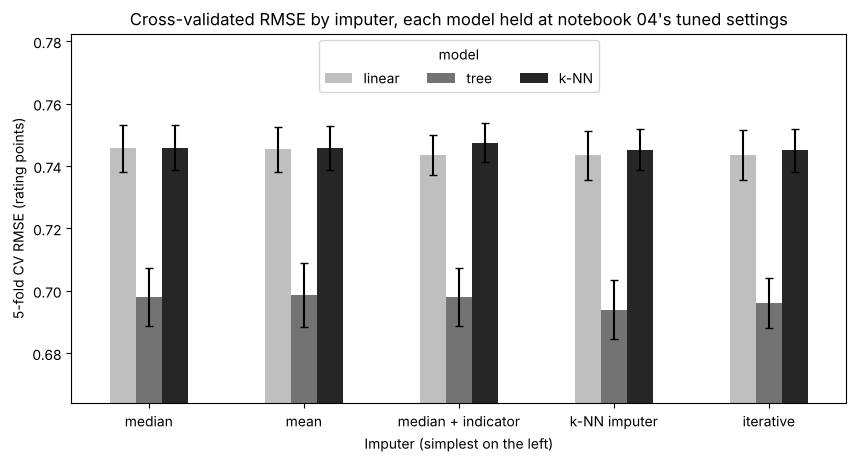

In [13]:
# [AI-assisted] Claude Code, 2026-11-10. Imputer comparison chart with the fold standard deviation as error bars; reviewed and edited by Ansel Weng.
ax = imputer_table.plot(kind="bar", yerr=imputer_sd, capsize=3, figsize=(10, 4.8), rot=0, color=["0.75", "0.45", "0.15"])
ax.set_ylim(imputer_table.values.min() - 0.03, imputer_table.values.max() + 0.035)
ax.set_title("Cross-validated RMSE by imputer, each model held at notebook 04's tuned settings")
ax.set_xlabel("Imputer (simplest on the left)")
ax.set_ylabel("5-fold CV RMSE (rating points)")
ax.legend(title="model", loc="upper center", ncol=3)
save("05_imputer_comparison.png")
plt.show()

**Takeaway: all five imputers are tied under decision 4d, so the simplest, median, is chosen.** For every model, every imputer is within 0.005 RMSE of the best. The largest gap is 0.0046 (mean, with the tree). The k-NN imputer is best for linear regression and the tree (0.7434 and 0.6940), and iterative is best for k-NN (0.7450). But the fold-to-fold standard deviation is 0.006 to 0.010, larger than any gap between imputers, so none of these differences can be told apart from which games landed in which fold. The two elaborate imputers also took 12 to 15 seconds against 1 to 2 for the simple ones.

Median + indicator no longer stands out (linear 0.7436 against 0.7457 for median). The strongest "this was unknown" signal is a missing mechanic list, and decision 3b's `mech_list_missing` flag already gives it to every imputer, so the indicator columns have little left to add. The tree's best imputer (k-NN, 0.0041 better than median) is the closest call to the margin. It is recorded here, but under the rule it is a tie.

## 7. Re-tune the regression tree on the imputed rows

### 7a. Grid search over maximum depth and minimum games per leaf

Notebook 04's grid (decision 6b), with the chosen imputer as the first step of the pipeline, by 5-fold cross-validation on every training game. If the best value sits on the edge of the grid, the range is widened (course directives §5.4).

In [14]:
# [AI-assisted] Claude Code, 2026-11-10. Tree grid search on the impute approach, with an edge check; reviewed and edited by Ansel Weng.
TREE_GRID = {"model__max_depth": [3, 4, 5, 6, 8, 10, 12, 15], "model__min_samples_leaf": [5, 20, 50, 100, 200]}

def grid_search(estimator, grid, X, y):
    search = GridSearchCV(estimator, grid, cv=folds, scoring="neg_root_mean_squared_error", n_jobs=-1)
    return search.fit(X, y)

def edge_check(search, grid):
    for param, values in grid.items():
        best = search.best_params_[param]
        if len(values) > 2 and best in (values[0], values[-1]) and not isinstance(best, str):
            print(f"  edge: {param} = {best} is at the end of the range {values}")

def cv_table(search, row, col):
    res = pd.DataFrame(search.cv_results_)
    return -res.pivot_table(index="param_" + row, columns="param_" + col, values="mean_test_score")

tree_imp = grid_search(pipe(IMPUTER, "tree"), TREE_GRID, X_train, y_train)
best_i = tree_imp.best_index_
print("impute approach, tree:", tree_imp.best_params_, f"| CV RMSE {-tree_imp.best_score_:.4f} (sd {tree_imp.cv_results_['std_test_score'][best_i]:.4f})")
edge_check(tree_imp, TREE_GRID)
cv_table(tree_imp, "model__max_depth", "model__min_samples_leaf").round(4)

impute approach, tree: {'model__max_depth': 12, 'model__min_samples_leaf': 50} | CV RMSE 0.6977 (sd 0.0094)


param_model__min_samples_leaf,5,20,50,100,200
param_model__max_depth,,,,,
3,0.7712,0.7712,0.7712,0.7712,0.7712
4,0.7427,0.7427,0.7425,0.7423,0.7426
5,0.7267,0.7265,0.7245,0.7259,0.7281
6,0.7174,0.7147,0.7145,0.7163,0.7210
8,0.7082,0.7030,0.7027,0.7074,0.7139
10,0.7134,0.7028,0.6981,0.7033,0.7119
12,0.7323,0.7049,0.6977,0.7025,0.7119
15,0.7532,0.7074,0.6980,0.7026,0.7119


### 7b. Sweeps: training versus validation RMSE

`validation_curve` reports, for each setting, the RMSE on the training folds and on the validation fold, averaged over the 5 folds. The test rows are not touched (decision 6c; notebook 04 drew its sweeps on the test rows). A gap that widens between the two curves is the overfitting signal.

In [15]:
# [AI-assisted] Claude Code, 2026-11-10. Helper for train-versus-validation sweeps from cross-validation; reviewed and edited by Ansel Weng.
def sweep(estimator, param, values, X, y):
    train_s, valid_s = validation_curve(estimator, X, y, param_name=param, param_range=values, cv=folds,
                                        scoring="neg_root_mean_squared_error", n_jobs=-1)
    return pd.DataFrame({"value": values, "train RMSE": -train_s.mean(axis=1), "validation RMSE": -valid_s.mean(axis=1)})

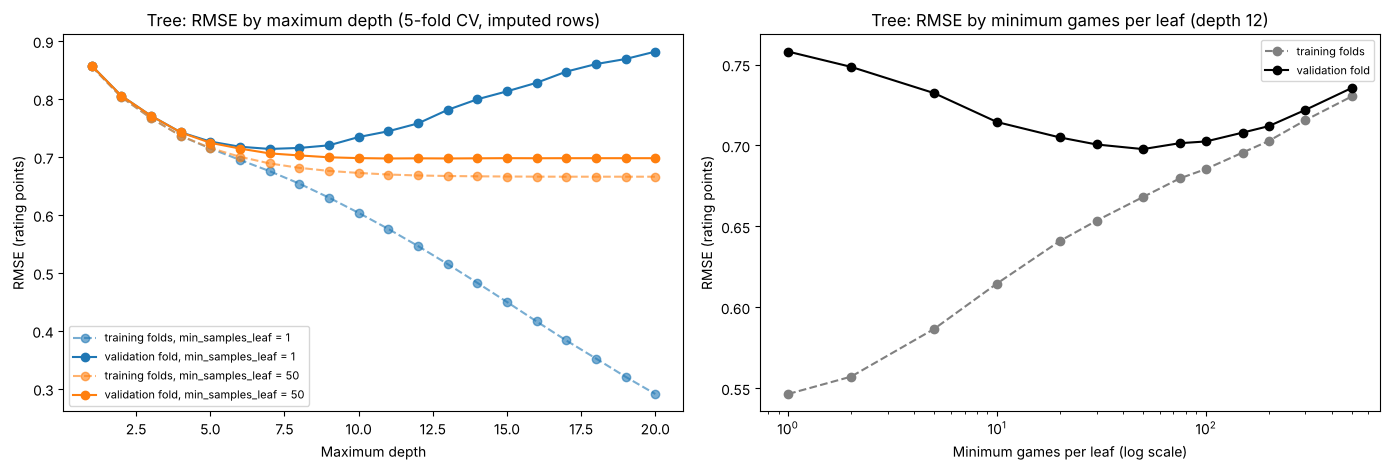

value                       1      2      3      4      5      6      7   \
leaf 1  train RMSE       0.856  0.803  0.767  0.737  0.715  0.695  0.676   
        validation RMSE  0.858  0.806  0.771  0.743  0.727  0.718  0.714   
leaf 50 train RMSE       0.856  0.803  0.767  0.737  0.716  0.700  0.689   
        validation RMSE  0.858  0.806  0.771  0.743  0.725  0.715  0.706   

value                       8      9      10     11     12     13     14  \
leaf 1  train RMSE       0.654  0.630  0.604  0.576  0.546  0.515  0.483   
        validation RMSE  0.716  0.720  0.734  0.744  0.758  0.781  0.800   
leaf 50 train RMSE       0.681  0.676  0.673  0.670  0.668  0.667  0.667   
        validation RMSE  0.703  0.700  0.698  0.697  0.698  0.698  0.698   

value                       15     16     17     18     19     20  
leaf 1  train RMSE       0.450  0.416  0.383  0.352  0.321  0.291  
        validation RMSE  0.813  0.828  0.847  0.860  0.869  0.882  
leaf 50 train RMSE       0.666  0.666  0.666  0.666  0.666  0.666  
        validation RMSE  0.698  0.698  0.698  0.698  0.698  0.698

In [16]:
# [AI-assisted] Claude Code, 2026-11-10. Depth sweep at leaf size 1 and at the tuned leaf size, and a leaf-size sweep at the tuned depth (decision 6d); reviewed and edited by Ansel Weng.
best_depth = tree_imp.best_params_["model__max_depth"]
best_leaf = tree_imp.best_params_["model__min_samples_leaf"]
depths = list(range(1, 21))
leaves = [1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 500]
depth_leaf1 = sweep(pipe(IMPUTER, "tree", min_samples_leaf=1), "model__max_depth", depths, X_train, y_train)
depth_leafbest = sweep(pipe(IMPUTER, "tree", min_samples_leaf=best_leaf), "model__max_depth", depths, X_train, y_train)
leaf_sweep = sweep(pipe(IMPUTER, "tree", max_depth=best_depth), "model__min_samples_leaf", leaves, X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for frame, colour, label in [(depth_leaf1, "tab:blue", "min_samples_leaf = 1"), (depth_leafbest, "tab:orange", f"min_samples_leaf = {best_leaf}")]:
    axes[0].plot(frame["value"], frame["train RMSE"], "o--", color=colour, alpha=0.6, label=f"training folds, {label}")
    axes[0].plot(frame["value"], frame["validation RMSE"], "o-", color=colour, label=f"validation fold, {label}")
axes[0].set_title("Tree: RMSE by maximum depth (5-fold CV, imputed rows)")
axes[0].set_xlabel("Maximum depth")
axes[0].set_ylabel("RMSE (rating points)")
axes[0].legend(fontsize=8)
axes[1].plot(leaf_sweep["value"], leaf_sweep["train RMSE"], "o--", color="0.5", label="training folds")
axes[1].plot(leaf_sweep["value"], leaf_sweep["validation RMSE"], "o-", color="black", label="validation fold")
axes[1].set_xscale("log")
axes[1].set_title(f"Tree: RMSE by minimum games per leaf (depth {best_depth})")
axes[1].set_xlabel("Minimum games per leaf (log scale)")
axes[1].set_ylabel("RMSE (rating points)")
axes[1].legend(fontsize=8)
plt.tight_layout()
save("05_tree_sweeps.png")
plt.show()
pd.concat({"leaf 1": depth_leaf1.set_index("value"), f"leaf {best_leaf}": depth_leafbest.set_index("value")}, axis=1).round(3).T

In [17]:
# [AI-assisted] Claude Code, 2026-11-10. Leaf-size sweep as a table; reviewed and edited by Ansel Weng.
leaf_sweep.set_index("value").round(3).T

value,1,2,5,10,20,30,50,75,100,150,200,300,500
train RMSE,0.546,0.557,0.587,0.615,0.641,0.654,0.668,0.680,0.685,0.696,0.703,0.716,0.730
validation RMSE,0.758,0.749,0.732,0.714,0.705,0.701,0.698,0.701,0.702,0.708,0.712,0.722,0.736


**Takeaway:** the best setting is depth 12 with at least 50 games per leaf (CV RMSE 0.6977, sd 0.0094). Neither value is on the edge of the grid, so no widening was needed. The surface is flat around it: depth 10, 12 and 15 at leaf 50 are within 0.0004 of each other. The sweeps show why the leaf limit matters. With one game per leaf (blue), validation RMSE is lowest at depth 7 (0.714) and climbs to 0.882 at depth 20, while training RMSE falls to 0.291: the classic overfitting gap. With at least 50 games per leaf (orange), validation RMSE flattens at about 0.698 from depth 10 on and never rises, because the leaf limit stops the tree from carving out tiny groups. At depth 12, leaf sizes below 20 overfit (0.758 at 1), sizes above 100 underfit (0.736 at 500, where training and validation RMSE nearly meet), and 50 is lowest.

## 8. Re-tune k-NN on the imputed rows

### 8a. Grid search over k, the weighting and the distance measure

k from notebook 04's values; `weights` equal or by distance; `p = 1` (Manhattan) or `p = 2` (Euclidean). The pipeline is imputer, then `StandardScaler`, then k-NN, so the scaler is also fitted on training folds only.

In [18]:
# [AI-assisted] Claude Code, 2026-11-10. k-NN grid search on the impute approach, with an edge check; reviewed and edited by Ansel Weng.
KNN_GRID = {"model__n_neighbors": [5, 10, 15, 20, 30, 40, 50, 75], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}
knn_imp = grid_search(pipe(IMPUTER, "k-NN"), KNN_GRID, X_train, y_train)
best_i = knn_imp.best_index_
print("impute approach, k-NN:", knn_imp.best_params_, f"| CV RMSE {-knn_imp.best_score_:.4f} (sd {knn_imp.cv_results_['std_test_score'][best_i]:.4f})")
edge_check(knn_imp, KNN_GRID)
res = pd.DataFrame(knn_imp.cv_results_)
-res.pivot_table(index="param_model__n_neighbors", columns=["param_model__p", "param_model__weights"], values="mean_test_score").round(4)

impute approach, k-NN: {'model__n_neighbors': 30, 'model__p': 1, 'model__weights': 'distance'} | CV RMSE 0.7277 (sd 0.0077)


param_model__p                  1                2        
param_model__weights     distance uniform distance uniform
param_model__n_neighbors                                  
5                          0.7651  0.7674   0.7840  0.7875
10                         0.7385  0.7440   0.7557  0.7621
15                         0.7311  0.7390   0.7472  0.7549
20                         0.7286  0.7377   0.7445  0.7533
30                         0.7277  0.7384   0.7459  0.7566
40                         0.7295  0.7413   0.7476  0.7591
50                         0.7314  0.7440   0.7492  0.7609
75                         0.7349  0.7480   0.7530  0.7650

### 8b. Sweeps of k, equal and distance weights

At the tuned distance measure. With distance weights, the training-fold RMSE is near zero by construction: each training game is its own nearest neighbour at distance zero, so it predicts itself (notebook 04, section 6). The equal-weight curves are therefore the fit diagnostic.

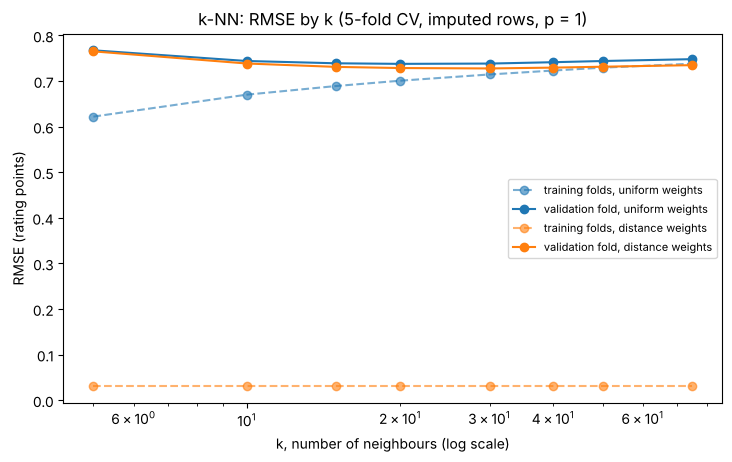

value                        5      10     15     20     30     40     50  \
uniform  train RMSE       0.622  0.670  0.689  0.701  0.714  0.723  0.729   
         validation RMSE  0.767  0.744  0.739  0.738  0.738  0.741  0.744   
distance train RMSE       0.031  0.031  0.031  0.031  0.031  0.031  0.031   
         validation RMSE  0.765  0.738  0.731  0.729  0.728  0.729  0.731   

value                        75  
uniform  train RMSE       0.738  
         validation RMSE  0.748  
distance train RMSE       0.031  
         validation RMSE  0.735

In [19]:
# [AI-assisted] Claude Code, 2026-11-10. k sweeps for both weightings at the tuned p (decision 7d); reviewed and edited by Ansel Weng.
best_p = knn_imp.best_params_["model__p"]
ks = KNN_GRID["model__n_neighbors"]
k_sweeps = {w: sweep(pipe(IMPUTER, "k-NN", weights=w, p=best_p), "model__n_neighbors", ks, X_train, y_train) for w in ["uniform", "distance"]}

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for w, colour in [("uniform", "tab:blue"), ("distance", "tab:orange")]:
    ax.plot(k_sweeps[w]["value"], k_sweeps[w]["train RMSE"], "o--", color=colour, alpha=0.6, label=f"training folds, {w} weights")
    ax.plot(k_sweeps[w]["value"], k_sweeps[w]["validation RMSE"], "o-", color=colour, label=f"validation fold, {w} weights")
ax.set_xscale("log")
ax.set_title(f"k-NN: RMSE by k (5-fold CV, imputed rows, p = {best_p})")
ax.set_xlabel("k, number of neighbours (log scale)")
ax.set_ylabel("RMSE (rating points)")
ax.legend(fontsize=8)
save("05_knn_k_sweep.png")
plt.show()
pd.concat({w: f.set_index("value") for w, f in k_sweeps.items()}, axis=1).round(3).T

**Takeaway:** the best setting is k = 30, distance weights, Manhattan distance (p = 1), with CV RMSE 0.7277 (sd 0.0077). k = 30 is inside the grid. **Manhattan distance is better than Euclidean at every k and both weightings**, by 0.015 to 0.02 (0.7277 against 0.7459 at k = 30 with distance weights), so the third hyperparameter was worth adding. Distance weighting beats equal weighting at every k. In the equal-weight sweep, the gap between training RMSE (0.622) and validation RMSE (0.767) is widest at k = 5 and narrows as k grows. Validation RMSE bottoms out at 0.738 for k = 20 to 30 and rises to 0.748 at k = 75 as neighbourhoods get too broad. Because the grid starts at k = 5 (decision 7b), the sweep does not show the extreme memorising at k = 1 that notebook 04's sweep did.

## 9. The drop approach, tuned the same way

Decision 5c: the same grids and the same folds object, on the 12,587 complete training games (notebook 04's training rows). There is nothing to impute, so the pipelines start at the model. The tree grid is notebook 04's, so this should reproduce notebook 04's tuned tree.

In [20]:
# [AI-assisted] Claude Code, 2026-11-10. Tree and k-NN grid searches on the complete training games only; reviewed and edited by Ansel Weng.
tree_drop = grid_search(pipe(None, "tree"), TREE_GRID, X_train_drop, y_train_drop)
knn_drop = grid_search(pipe(None, "k-NN"), KNN_GRID, X_train_drop, y_train_drop)
tuned = pd.DataFrame([
    {"approach": "drop", "model": "tree", "settings": tree_drop.best_params_, "CV RMSE": -tree_drop.best_score_, "CV sd": tree_drop.cv_results_["std_test_score"][tree_drop.best_index_], "training games": len(y_train_drop)},
    {"approach": "drop", "model": "k-NN", "settings": knn_drop.best_params_, "CV RMSE": -knn_drop.best_score_, "CV sd": knn_drop.cv_results_["std_test_score"][knn_drop.best_index_], "training games": len(y_train_drop)},
    {"approach": "impute", "model": "tree", "settings": tree_imp.best_params_, "CV RMSE": -tree_imp.best_score_, "CV sd": tree_imp.cv_results_["std_test_score"][tree_imp.best_index_], "training games": len(y_train)},
    {"approach": "impute", "model": "k-NN", "settings": knn_imp.best_params_, "CV RMSE": -knn_imp.best_score_, "CV sd": knn_imp.cv_results_["std_test_score"][knn_imp.best_index_], "training games": len(y_train)},
])
for name, search, grid in [("drop tree", tree_drop, TREE_GRID), ("drop k-NN", knn_drop, KNN_GRID)]:
    print(name, search.best_params_); edge_check(search, grid)
tuned.round(4)

drop tree {'model__max_depth': 10, 'model__min_samples_leaf': 50}
drop k-NN {'model__n_neighbors': 30, 'model__p': 1, 'model__weights': 'distance'}


,approach,model,settings,CV RMSE,CV sd,training games
0,drop,tree,"{'model__max_depth': 10, 'model__min_samples_l...",0.6797,0.0051,12587
1,drop,k-NN,"{'model__n_neighbors': 30, 'model__p': 1, 'mod...",0.7099,0.0130,12587
2,impute,tree,"{'model__max_depth': 12, 'model__min_samples_l...",0.6977,0.0094,14964
3,impute,k-NN,"{'model__n_neighbors': 30, 'model__p': 1, 'mod...",0.7277,0.0077,14964


These cross-validated RMSEs are **not** comparable across approaches. The impute approach is scored on all training games, including the harder incomplete ones; the drop approach on complete games only. Section 10 makes the like-for-like comparison.

## 10. Drop versus impute, like-for-like, by cross-validation

Decision 9a. The impute approach's training games are split into the same 5 folds. In each fold:

- the **impute** model (tuned settings, chosen imputer) is fitted on every game in the training folds;
- the **drop** model (its own tuned settings) is fitted on only the complete games in the training folds;
- both are scored on only the **complete** games in the validation fold, so they are judged on identical games.

Decision 9b: impute is adopted unless it is more than 0.005 RMSE worse than drop. As with 4d-ii, the rule must hold for both the tree and k-NN. The test rows are not used here.

In [21]:
# [AI-assisted] Claude Code, 2026-11-10. Fold-by-fold like-for-like RMSE of the two approaches on complete validation games; reviewed and edited by Ansel Weng.
X_train_drop_all = build_inputs(train_df, mech_drop, cat_drop, flags=False)   # drop-approach inputs for every training game; only complete rows are used
final_models = {("impute", "tree"): tree_imp.best_estimator_, ("impute", "k-NN"): knn_imp.best_estimator_,
                ("drop", "tree"): tree_drop.best_estimator_, ("drop", "k-NN"): knn_drop.best_estimator_}
rows = []
for fold, (tr, va) in enumerate(folds.split(X_train)):
    tr_cc, va_cc = tr[train_complete[tr]], va[train_complete[va]]
    for model_name in ["tree", "k-NN"]:
        m_imp = clone(final_models[("impute", model_name)]).fit(X_train.iloc[tr], y_train.iloc[tr])
        m_drop = clone(final_models[("drop", model_name)]).fit(X_train_drop_all.iloc[tr_cc], y_train.iloc[tr_cc])
        y_va = y_train.iloc[va_cc]
        rows.append({"fold": fold + 1, "model": model_name,
                     "drop": np.sqrt(mean_squared_error(y_va, m_drop.predict(X_train_drop_all.iloc[va_cc]))),
                     "impute": np.sqrt(mean_squared_error(y_va, m_imp.predict(X_train.iloc[va_cc]))),
                     "complete validation games": len(va_cc)})
like = pd.DataFrame(rows)
like["impute - drop"] = like["impute"] - like["drop"]
summary = like.groupby("model")[["drop", "impute", "impute - drop"]].agg(["mean", "std"])
display(like.round(4))
summary.round(4)

,fold,model,drop,impute,complete validation games,impute - drop
0,1,tree,0.6808,0.6727,2501,-0.0082
1,1,k-NN,0.7125,0.7162,2501,0.0036
2,2,tree,0.6968,0.6930,2531,-0.0038
3,2,k-NN,0.7211,0.7185,2531,-0.0025
4,3,tree,0.6755,0.6668,2519,-0.0087
5,3,k-NN,0.6987,0.6967,2519,-0.0019
6,4,tree,0.6740,0.6705,2517,-0.0036
7,4,k-NN,0.7052,0.7062,2517,0.0010
8,5,tree,0.6727,0.6760,2519,0.0033
9,5,k-NN,0.7041,0.7053,2519,0.0012


drop          impute         impute - drop        
         mean     std    mean     std          mean     std
model                                                      
k-NN   0.7083  0.0087  0.7086  0.0088        0.0003  0.0025
tree   0.6800  0.0099  0.6758  0.0102       -0.0042  0.0048

In [22]:
# [AI-assisted] Claude Code, 2026-11-10. Decision 9b applied; reviewed and edited by Ansel Weng.
diff = like.groupby("model")["impute - drop"].mean()
impute_ok = diff <= MARGIN
APPROACH = "impute" if impute_ok.all() else "drop"
for model_name in ["tree", "k-NN"]:
    verdict = "within the margin" if impute_ok[model_name] else "more than 0.005 worse"
    print(f"{model_name}: impute - drop = {diff[model_name]:+.4f} RMSE on complete validation games -> {verdict}")
print("decision:", APPROACH)

tree: impute - drop = -0.0042 RMSE on complete validation games -> within the margin
k-NN: impute - drop = +0.0003 RMSE on complete validation games -> within the margin
decision: impute


**Takeaway: on identical complete games, imputing is as good as dropping, so impute is adopted.** The drop approach's tuned tree is notebook 04's (depth 10, 50 per leaf, CV RMSE 0.680), as expected from the same rows and grid. Its k-NN settles on the same k = 30, distance weights and Manhattan distance as the impute approach. On the complete validation games, the imputed tree is 0.0042 RMSE *better* than the dropped one (0.6758 against 0.6800, better in 4 of 5 folds). The imputed k-NN is 0.0003 worse (0.7086 against 0.7083), well inside the 0.005 margin. Both pass decision 9b's rule. Training on the 2,377 extra imputed games costs nothing on the games we already had, and the impute approach can also predict games with a missing input.

## 11. Score the test rows once

Every model is fitted on its own training games and scored once. Ground rule 3: RMSE, MAE and R², next to a `DummyRegressor` that predicts each approach's training mean.

- **complete test games** (5,395, notebook 04's test rows): both approaches can predict them, so this is the like-for-like check.
- **all test games**: what the impute approach delivers. The drop approach has no prediction for a game with a missing input.
- **test games with a missing input**: how the imputed model does on exactly the games that dropping throws away.

In [23]:
# [AI-assisted] Claude Code, 2026-11-10. Fit the final models and score every test set once; reviewed and edited by Ansel Weng.
def metrics(y, pred):
    return {"games": len(y), "RMSE": np.sqrt(mean_squared_error(y, pred)), "MAE": mean_absolute_error(y, pred), "R2": r2_score(y, pred)}

fitted = {("drop", "baseline"): DummyRegressor(strategy="mean").fit(X_train_drop, y_train_drop),
          ("impute", "baseline"): DummyRegressor(strategy="mean").fit(X_train, y_train)}
fitted[("drop", "tree")] = final_models[("drop", "tree")]        # GridSearchCV refits the best settings on all of each approach's training games
fitted[("drop", "k-NN")] = final_models[("drop", "k-NN")]
fitted[("impute", "tree")] = final_models[("impute", "tree")]
fitted[("impute", "k-NN")] = final_models[("impute", "k-NN")]

test_sets = {
    "complete test games": {"drop": (X_test_drop, y_test_drop), "impute": (X_test[test_complete], y_test[test_complete])},
    "all test games": {"impute": (X_test, y_test)},
    "test games with a missing input": {"impute": (X_test[~test_complete], y_test[~test_complete])},
}
rows = []
for set_name, by_approach in test_sets.items():
    for approach, (X_, y_) in by_approach.items():
        for model_name in ["baseline", "tree", "k-NN"]:
            rows.append({"test set": set_name, "approach": approach, "model": model_name, **metrics(y_, fitted[(approach, model_name)].predict(X_))})
final = pd.DataFrame(rows).set_index(["test set", "approach", "model"])
final.round(3)

games   RMSE    MAE     R2
test set                        approach model                               
complete test games             drop     baseline   5395  0.903  0.709 -0.000
                                         tree       5395  0.684  0.522  0.425
                                         k-NN       5395  0.716  0.545  0.370
                                impute   baseline   5395  0.904  0.712 -0.004
                                         tree       5395  0.682  0.520  0.429
                                         k-NN       5395  0.719  0.547  0.366
all test games                  impute   baseline   6415  0.927  0.728 -0.000
                                         tree       6415  0.702  0.532  0.427
                                         k-NN       6415  0.730  0.556  0.379
test games with a missing input impute   baseline   1020  1.037  0.810 -0.058
                                         tree       1020  0.796  0.596  0.376
                                         k-NN       1020  0.789  0.605  0.386

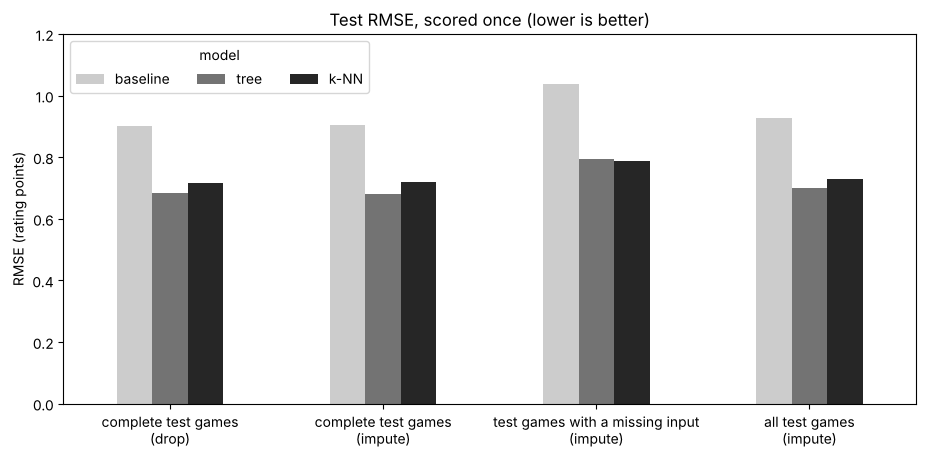

In [24]:
# [AI-assisted] Claude Code, 2026-11-10. Test RMSE by test set, approach and model; reviewed and edited by Ansel Weng.
plot_df = final["RMSE"].unstack("model")[["baseline", "tree", "k-NN"]]
plot_df = plot_df.loc[[("complete test games", "drop"), ("complete test games", "impute"),
                       ("test games with a missing input", "impute"), ("all test games", "impute")]]
plot_df.index = [f"{s}\n({a})" for s, a in plot_df.index]
ax = plot_df.plot(kind="bar", figsize=(11, 4.8), rot=0, color=["0.8", "0.45", "0.15"])
ax.set_title("Test RMSE, scored once (lower is better)")
ax.set_ylabel("RMSE (rating points)")
ax.set_xlabel("")
ax.legend(title="model", loc="upper left", ncol=3)
ax.set_ylim(0, 1.2)
save("05_drop_vs_impute.png")
plt.show()

**Takeaway: the test rows confirm the cross-validation.** On notebook 04's 5,395 complete test games, the drop approach's tree reproduces notebook 04 exactly (RMSE 0.684, MAE 0.522, R² 0.425). The imputed tree is marginally better (0.682, 0.520, 0.429). k-NN is 0.716 dropped against 0.719 imputed, both better than notebook 04's 0.736 because of Manhattan distance.

**What imputing adds is the 1,020 test games with a missing input (16% of the test set)**, which the drop approach cannot score at all. They are harder: the baseline's RMSE on them is 1.037, against 0.904 on complete games. Even so, the tree reaches 0.796 (R² 0.376) and k-NN 0.789 (R² 0.386), so the models still explain a similar share of their variance. Across **all 6,415 test games**, the imputed tree scores RMSE 0.702, MAE 0.532, R² 0.427, against 0.927 for the baseline; k-NN scores 0.730, 0.556 and 0.379.

## 12. What the tuned tree uses on the imputed rows

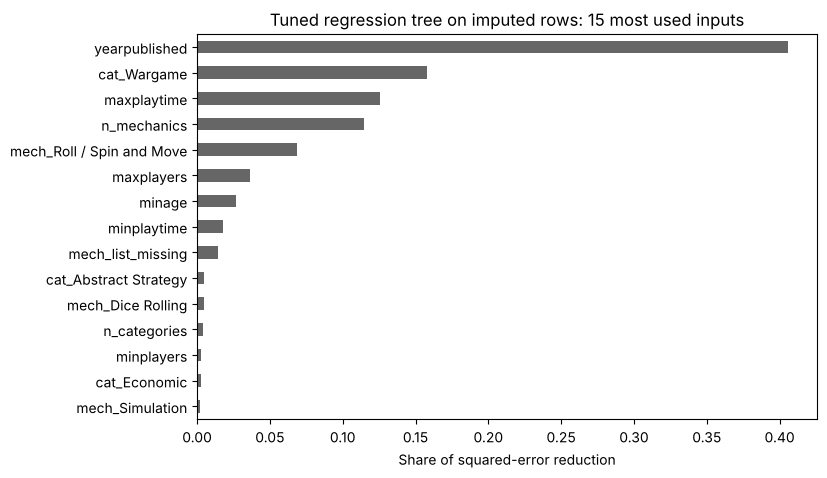

importance of the list flags and 'was missing' columns combined: 0.014


yearpublished                0.405
cat_Wargame                  0.158
maxplaytime                  0.126
n_mechanics                  0.114
mech_Roll / Spin and Move    0.069
maxplayers                   0.036
minage                       0.026
minplaytime                  0.018
mech_list_missing            0.014
cat_Abstract Strategy        0.005
mech_Dice Rolling            0.004
n_categories                 0.004
minplayers                   0.003
cat_Economic                 0.003
mech_Simulation              0.002
dtype: float64

In [25]:
# [AI-assisted] Claude Code, 2026-11-10. Feature importance of the tuned impute-approach tree, including any 'was missing' columns the imputer added; reviewed and edited by Ansel Weng.
tree_final = fitted[("impute", "tree")]
names = tree_final[:-1].get_feature_names_out() if len(tree_final) > 1 else X_train.columns
importance = pd.Series(tree_final[-1].feature_importances_, index=names).sort_values(ascending=False)
ax = importance.head(15).plot(kind="barh", color="0.4", figsize=(8, 5))
ax.invert_yaxis()
ax.set_title("Tuned regression tree on imputed rows: 15 most used inputs")
ax.set_xlabel("Share of squared-error reduction")
save("05_tree_feature_importance.png")
plt.show()
flag_like = importance[[n for n in importance.index if "missing" in n]]
print("importance of the list flags and 'was missing' columns combined:", round(flag_like.sum(), 3))
importance.head(15).round(3)

**Takeaway:** year of publication is still the dominant input (0.405 of the squared-error reduction, against 0.428 in notebook 04). It is followed by the wargame category (0.158), maximum play time (0.126) and the number of mechanics (0.114). `mech_list_missing` is ninth at 0.014: the tree does use "this game has no mechanic list", but only a little, so the leakage concern in section 5 has little effect on the scores. Minimum age falls from 0.155 in notebook 04 to 0.026 while the wargame category rises from 0.017. A tree credits whichever of two related inputs it happens to split on first, so these shares can trade places between runs and should not be over-read.

## 13. The call for the group chat

The cell below is the code for the other predictive notebooks (tasks 2, 3, 4 and 10). It replaces notebook 04's `dropna` cell and its split and input cells. It is run here to check that it rebuilds exactly this notebook's rows, split and inputs.

**Task 4 (notebook 08) is the exception:** it trains on games up to a cut-off year and tests on later years, so ground rule 2's split does not apply there. Take the row rule, `build_inputs` with the two flags, and the imputer from this cell, but not the two `train_test_split` lines; count the most common mechanics and categories on that notebook's own training years.

In [26]:
# [AI-assisted] Claude Code, 2026-11-10. Copy-paste cell for the other predictive notebooks, checked against this notebook; reviewed and edited by Ansel Weng.
saved_X_train, saved_X_test, saved_ids = X_train.copy(), X_test.copy(), test_df["id"].copy()   # this notebook's versions, for the check at the end

# ---- paste from here: rows, split, inputs and imputer as settled by task 1 (notebooks/05_imputation_tuning_ansel.ipynb) ----
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
gaps = games[numeric_cols].isna().sum(axis=1)
data = games[games["yearpublished"].notna() & (gaps < 4)].copy()           # drop no-year games and games missing 4+ of the 8 inputs
data["complete"] = data[numeric_cols].notna().all(axis=1)
tr_c, te_c = train_test_split(data[data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)    # = notebook 04's split
tr_i, te_i = train_test_split(data[~data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)
train_df, test_df = pd.concat([tr_c, tr_i], ignore_index=True), pd.concat([te_c, te_i], ignore_index=True)
y_train, y_test = train_df["average"], test_df["average"]

def build_inputs(frame, mechanics, categories):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=mechanics, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=categories, fill_value=0).add_prefix("cat_")
    flags = pd.DataFrame({"mech_list_missing": frame["boardgamemechanic"].isna().astype(int),
                          "cat_list_missing": frame["boardgamecategory"].isna().astype(int)}, index=frame.index)
    return pd.concat([X, mech, cat, flags], axis=1)

top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index
X_train, X_test = build_inputs(train_df, top_mech, top_cat), build_inputs(test_df, top_mech, top_cat)
# Then make the imputer the first step of every model's Pipeline, for example:
#   Pipeline([("impute", <chosen imputer, printed below>), ("scale", StandardScaler()), ("model", KNeighborsRegressor(...))])
# ---- paste to here ----

assert X_train.equals(saved_X_train) and X_test.equals(saved_X_test) and test_df["id"].equals(saved_ids)
print("the pasted cell rebuilds this notebook's rows, split and inputs exactly:", X_train.shape, X_test.shape)

the pasted cell rebuilds this notebook's rows, split and inputs exactly: (14964, 45) (6415, 45)


In [27]:
# [AI-assisted] Claude Code, 2026-11-10. The decision, tuned settings and test scores, printed for the group-chat post; reviewed and edited by Ansel Weng.
imputer_code = {"median": 'SimpleImputer(strategy="median")', "mean": 'SimpleImputer(strategy="mean")',
                "median + indicator": 'SimpleImputer(strategy="median", add_indicator=True)',
                "k-NN imputer": 'StandardScaler() then KNNImputer(n_neighbors=5)', "iterative": 'IterativeImputer(max_iter=10, random_state=0)'}
print("Approach:", APPROACH, "| imputer:", IMPUTER, "->", imputer_code[IMPUTER])
print("Tree (impute):", tree_imp.best_params_, "| k-NN (impute):", knn_imp.best_params_)
print(final.loc["all test games"].round(3).to_string())
print("Notebook 12 cites 'median + indicator' as the prediction imputer:", "still true" if IMPUTER == "median + indicator" else f"update to '{IMPUTER}'")

Approach: impute | imputer: median -> SimpleImputer(strategy="median")
Tree (impute): {'model__max_depth': 12, 'model__min_samples_leaf': 50} | k-NN (impute): {'model__n_neighbors': 30, 'model__p': 1, 'model__weights': 'distance'}
                   games   RMSE    MAE     R2
approach model                               
impute   baseline   6415  0.927  0.728 -0.000
         tree       6415  0.702  0.532  0.427
         k-NN       6415  0.730  0.556  0.379
Notebook 12 cites 'median + indicator' as the prediction imputer: update to 'median'


### Post for the group chat

> **Task 1 is in: impute, don't drop** (`notebooks/05_imputation_tuning_ansel.ipynb`).
>
> **Rows:** keep 21,379 of 21,631 games. Drop only the 195 with no year and the games missing 4+ of the 8 numeric inputs (252 in total, 1.16%). **Split:** complete games split exactly as notebook 04 (`test_size=0.3, random_state=1`), games with a gap split the same way, then combined: 14,964 training and 6,415 test games. **Inputs:** notebook 04's, plus two 0/1 flags, `mech_list_missing` and `cat_list_missing`. **Imputer:** `SimpleImputer(strategy="median")` as the first step of every model's `Pipeline`.
>
> **Why:** (1) games with a gap rate lower (6.17 against 6.47) and have fewer raters, so dropping them biases the rows. (2) On identical complete games, imputing is as good as dropping (tree 0.004 RMSE better, k-NN 0.0003 worse, by cross-validation). (3) It lets us score 16% more test games. (4) All five imputers tested (mean, median, median + indicator, k-NN, iterative) were within 0.005 RMSE of each other for linear regression, the tree and k-NN, so we take the simplest.
>
> **Tuned on the imputed rows:** tree `max_depth=12, min_samples_leaf=50`; k-NN `n_neighbors=30, weights="distance", p=1` (Manhattan beats Euclidean everywhere). **Test, all 6,415 games:** tree RMSE 0.702, MAE 0.532, R² 0.427; k-NN 0.730, 0.556, 0.379; baseline 0.927.
>
> **Code:** paste the cell in section 13 in place of notebook 04's `dropna`, split and input cells.

**Notebook 12 needs one line changed.** Its table of choices says "Notebook 05's median + indicator was chosen for prediction". It should now read "median". Its notes line ("`KNNImputer(n_neighbors=5)`, the same setting notebook 05 tested") and its two references to the bias in incomplete games still hold.

## 14. What did not work, and notes

- **More elaborate imputers did not pay off.** The k-NN and iterative imputers took 12 to 15 seconds, against 1 to 2 for median and mean, and improved no model by more than 0.005 RMSE. The tree's 0.0041 gain with the k-NN imputer was the closest call; it is kept in section 6 as evidence.
- **The "was missing" indicators added little once the list flags were in.** Median + indicator was only 0.002 better than median for linear regression and 0.0016 worse for k-NN.
- **Imputing did not make the complete-game predictions noticeably better.** The tree improved by 0.002 to 0.004 and k-NN was flat. The gain from imputing is coverage, not accuracy on the games we already had.
- **An unconstrained deep tree overfits badly.** Validation RMSE reaches 0.882 at depth 20 with one game per leaf; the leaf-size limit is what makes depth safe.
- **Euclidean distance was worse for k-NN** than Manhattan at every k, by 0.015 to 0.02 RMSE. Notebook 04 used only Euclidean.
- **Two caveats on the cross-validation numbers.** (1) As in notebook 04, the list of most common mechanics and categories is counted once on all training games, not inside each fold; it only decides which 35 columns exist. (2) The like-for-like comparison in section 10 uses the same folds the settings were tuned on, so both approaches' numbers are slightly optimistic, equally. The test rows in section 11 are the unbiased check, and they agree.
- **Decision 9b's rule was applied to both models** (tree and k-NN), in the same spirit as decision 4d-ii. The two models agreed, so the choice of rule did not change the outcome.

Reading this notebook:

- One split is used throughout: the complete games split exactly as notebook 04 (70/30, `random_state=1`), the games with a gap split the same way.
- Every number labelled "CV" comes from the same `KFold(n_splits=5, shuffle=True, random_state=0)` on training games only. Every number labelled "test" comes from scoring once, at the end.
- Every imputer and scaler sits inside a `Pipeline` and is fitted on training rows only.
- Figures are saved to `figures/` with the prefix `05_`.